# Predikcija dnevne potrošnje kalorija

Potrošnja kalorija predstavlja ključni faktor u planiranju fizičke aktivnosti,
regulaciji telesne mase i očuvanju zdravlja. Tačna procena dnevne potrošnje kalorija može pomoći pojedincima da prilagode ishranu i trening svojim ciljevima.


## Opis skupa podataka

Skup podataka korišćen u ovom projektu preuzet je sa platforme Kaggle i sadrži
informacije o fizičkim karakteristikama ispitanika i njihovoj potrošnji kalorija
tokom fizičke aktivnosti.
[Link](https://www.kaggle.com/datasets/ruchikakumbhar/calories-burnt-prediction)

Podaci iz dataset-a:
- User_ Id - jedinstveni identifikator korisnika
- Gender – pol ispitanika
- Age – starost (u godinama)
- Height – visina (u centimetrima)
- Weight – telesna težina (u kilogramima)
- Duration – trajanje aktivnosti (u minutima)
- Heart_rate - broj otkucaja srca tokom aktivnosti (u otkucajima po minuti)
- Body_temp - telesna temperatura tokom aktivnosti (izražena u stepenima Celzijusa)
- Calories – potrošene kalorije (ciljna promenljiva)


## Cilj projekta

Cilj ovog projekta je razviti sistem koji predviđa potrošnju kalorija korisnika na osnovu fizičkih aktivnosti i ostalih parametara.

## Očekivani rezultat
Očekivani rezultat je da dobijem model koji sa visokom tačnošću predviđa potrošnju kalorija i da pokažem da napredniji modeli poput Random Forest-a daju bolje rezultate od jednostavnih linearnih modela.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("calories.csv")

data.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68,190.0,94.0,29.0,105.0,40.8,231.0
1,14861698,female,20,166.0,60.0,14.0,94.0,40.3,66.0
2,11179863,male,69,179.0,79.0,5.0,88.0,38.7,26.0
3,16180408,female,34,179.0,71.0,13.0,100.0,40.5,71.0
4,17771927,female,27,154.0,58.0,10.0,81.0,39.8,35.0


In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      15000 non-null  object 
 2   Age         15000 non-null  int64  
 3   Height      15000 non-null  float64
 4   Weight      15000 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  15000 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  float64
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB


In [3]:
data.describe()

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,1.500000e+04,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,1.497736e+07,42.789800,174.465133,74.966867,15.530600,95.518533,40.025453,89.539533
std,2.872851e+06,16.980264,14.258114,15.035657,8.319203,9.583328,0.779230,62.456978
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,88.000000,39.600000,35.000000
50%,1.499728e+07,39.000000,175.000000,74.000000,16.000000,96.000000,40.200000,79.000000
75%,1.744928e+07,56.000000,185.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,1.999965e+07,79.000000,222.000000,132.000000,30.000000,128.000000,41.500000,314.000000


### Vizualizacija

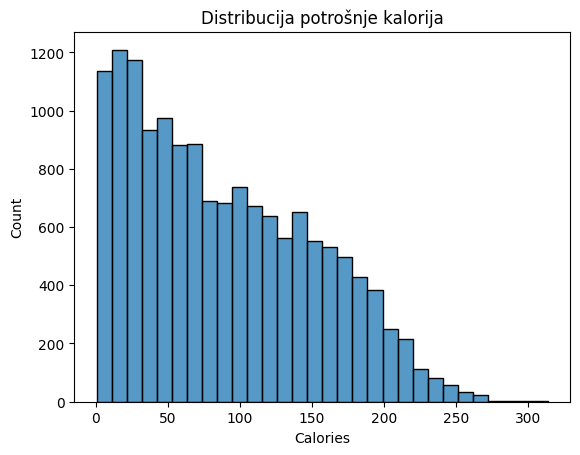

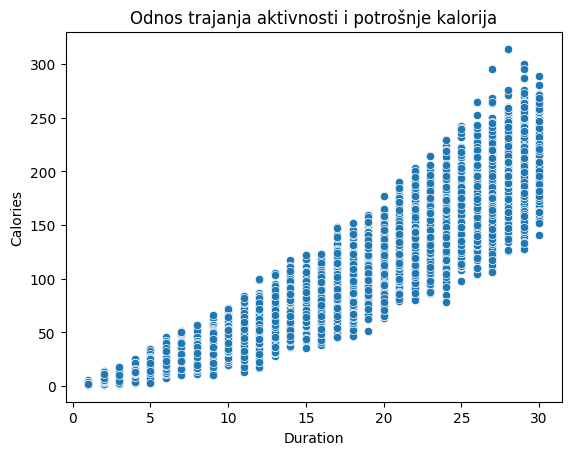

In [4]:

plt.figure()
sns.histplot(data["Calories"], bins=30)
plt.title("Distribucija potrošnje kalorija")
plt.show()

plt.figure()
sns.scatterplot(x="Duration", y="Calories", data=data)
plt.title("Odnos trajanja aktivnosti i potrošnje kalorija")
plt.show()


Histogram prikazuje distribuciju potrošnje kalorija u datasetu. Može se uočiti da je raspodela desno asimetrična, odnosno da veći broj uzoraka ima niže vrednosti potrošenih kalorija, dok se kako vrednosti kalorija rastu broj uzoraka postepeno smanjuje. Ovo ukazuje da su u datasetu zastupljenije aktivnosti nižeg intenziteta.

Takva raspodela može uticati na performanse modela mašinskog učenja, jer model ima više podataka za učenje u nižem opsegu vrednosti, dok su visoke vrednosti kalorija slabije predstavljene. Zbog toga postoji mogućnost da model bude manje precizan u predikciji većih vrednosti potrošnje kalorija.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

### Uklanjanje kolone User_ID i enkodiranje Gender

In [6]:
data_model = data.drop("User_ID", axis=1)
le = LabelEncoder()
data_model["Gender"] = le.fit_transform(data_model["Gender"])

### Vizuelna analiza pre skaliranja (histogrami i korelacija)

In [7]:
numeric_features = ["Age", "Height", "Weight", "Duration", "Heart_Rate", "Body_Temp"]

### Histogrami

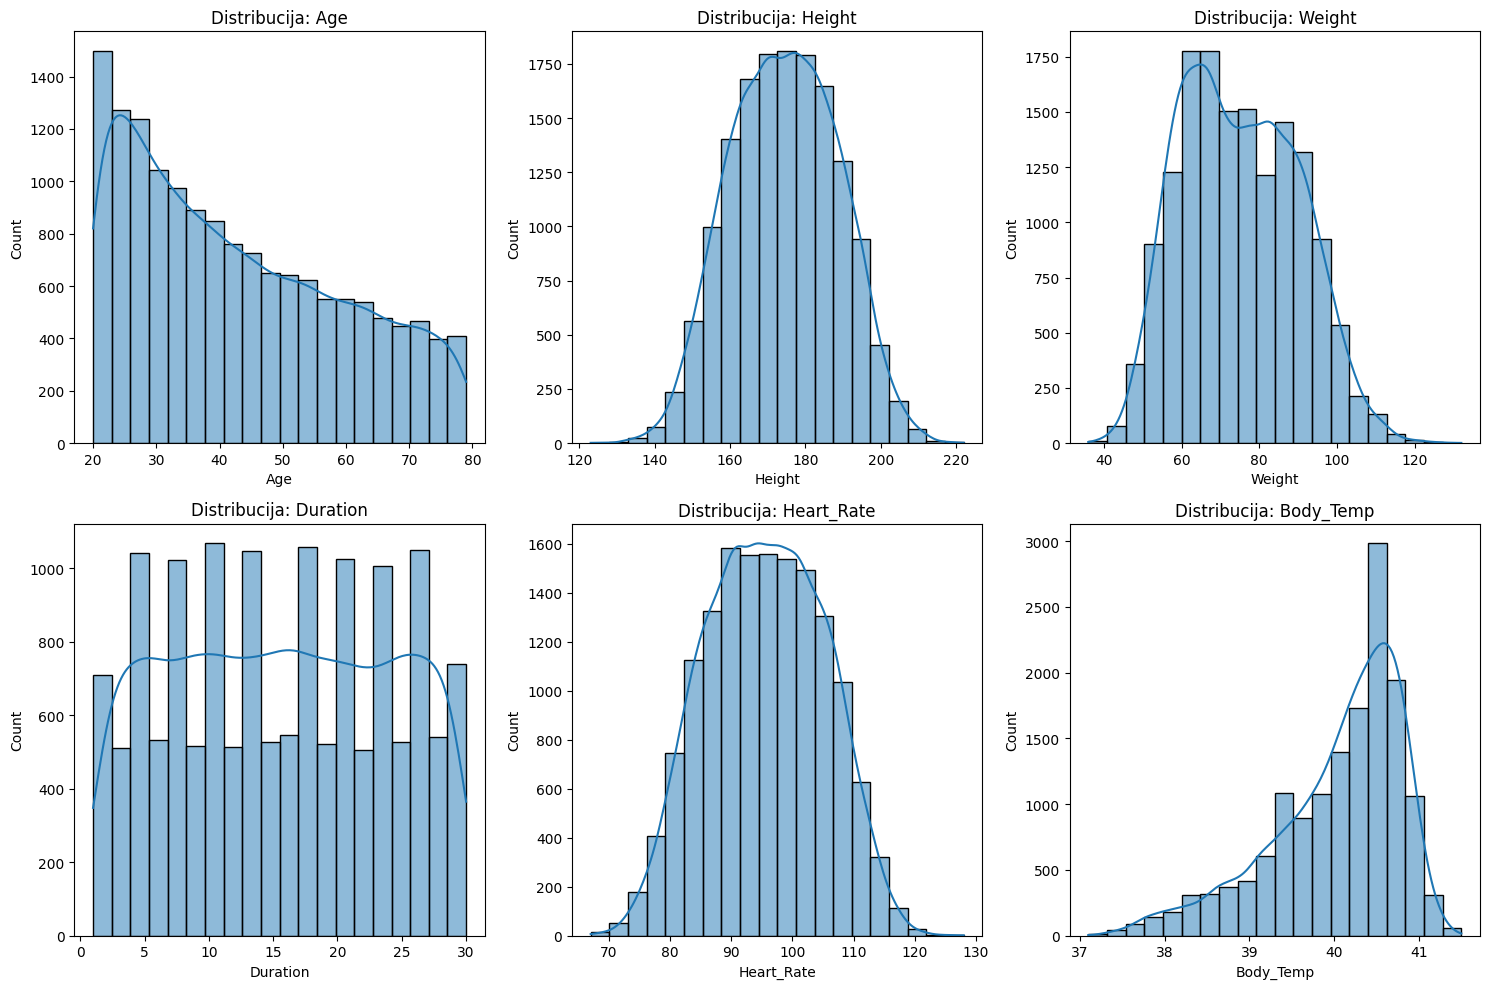

In [8]:
plt.figure(figsize=(15,10))
for i, feature in enumerate(numeric_features):
    plt.subplot(2,3,i+1)
    sns.histplot(data_model[feature], bins=20, kde=True)
    plt.title(f"Distribucija: {feature}")
plt.tight_layout()
plt.show()

Histogrami prikazuju distribuciju numeričkih varijabli. Primećuje se da su visina, težina i srčani puls približno normalno raspodeljeni, dok je starost asimetrično raspoređena. Trajanje aktivnosti ima uniformnu distribuciju, što ukazuje na ravnomernu zastupljenost svih intervala. Ovakva analiza je ključna za izbor skaliranja i modela mašinskog učenja.

### Korelaciona matrica 

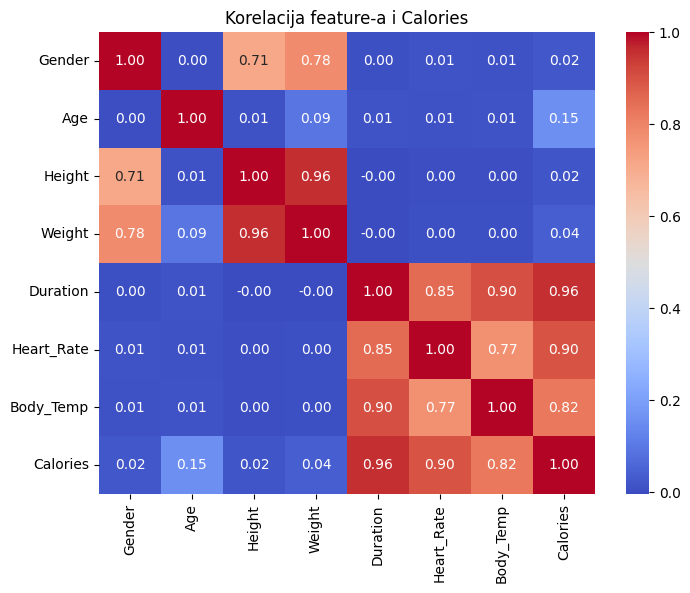

In [9]:
plt.figure(figsize=(8,6))
sns.heatmap(data_model.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korelacija feature-a i Calories")
plt.show()

Analizom korelacione matrice uočeno je da su najznačajniji faktori za predikciju potrošnje kalorija trajanje fizičke aktivnosti (r = 0.96), broj otkucaja srca (r = 0.90) i telesna temperatura (r = 0.82). Ovi rezultati potvrđuju da intenzitet i dužina aktivnosti imaju ključan uticaj na energetsku potrošnju.

Sa druge strane, demografske karakteristike kao što su pol, visina i težina pokazuju vrlo nisku korelaciju sa potrošenim kalorijama, što ukazuje da imaju ograničen direktan uticaj u modelu.

Takođe, primećena je visoka korelacija između visine i težine (r = 0.96), što ukazuje na postojanje multikolinearnosti među atributima.

### Odvajanje inputa (X) i ciljne promenljive (y)

In [10]:
X = data_model.drop("Calories", axis=1)
y = data_model["Calories"]

### Skaliranje numeričkih feature-a

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Podela na train i test set (80% / 20%)

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

### Provera

In [13]:
print("Predobrada završena!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Predobrada završena!
X_train shape: (12000, 7)
X_test shape: (3000, 7)
y_train shape: (12000,)
y_test shape: (3000,)


### Treniranje modela

In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Linear Regression

In [15]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

### Evaluacija Linear Regression

In [16]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression:")
print("MAE:", round(mae_lr,2))
print("MSE:", round(mse_lr,2))
print("R²:", round(r2_lr,2))
print("\n")

Linear Regression:
MAE: 8.44
MSE: 132.0
R²: 0.97




### Random Forest Regressor

In [17]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

### Evaluacija Random Forest

In [18]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regressor:")
print("MAE:", round(mae_rf,2))
print("MSE:", round(mse_rf,2))
print("R²:", round(r2_rf,2))

Random Forest Regressor:
MAE: 1.72
MSE: 7.18
R²: 1.0


## Vizuelna analiza performansi

### Scatter plot: stvarne vs predviđene kalorije (Random Forest)

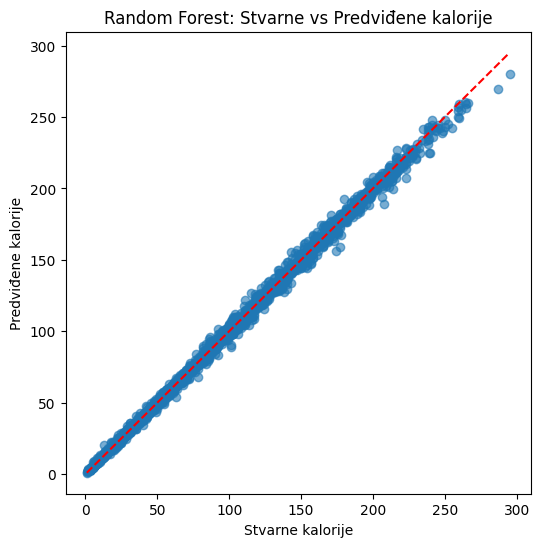

In [19]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.6)
plt.xlabel("Stvarne kalorije")
plt.ylabel("Predviđene kalorije")
plt.title("Random Forest: Stvarne vs Predviđene kalorije")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

Random Forest model pokazuje visok stepen tačnosti u predikciji kalorijske potrošnje. Većina predviđenih vrednosti nalazi se blizu idealne linije y = x, što ukazuje na dobru usklađenost između stvarnih i predviđenih vrednosti. Manja odstupanja se primećuju na višim vrednostima kalorija, ali ona ne utiču značajno na ukupne performanse modela.

## Rezultat

Na osnovu evaluacije modela, Random Forest Regressor daje bolje rezultate od Linear Regression:

- MAE i MSE su niži kod Random Forest-a, što znači manju prosečnu grešku i manje ekstremnih odstupanja.
- R² score je bliži 1 kod Random Forest-a, što pokazuje da model bolje objašnjava varijansu podataka.
- Scatter plot pokazuje da su predviđene vrednosti (plave tačke) blizu linije savršene predikcije (crvena isprekidana linija).

Ograničenja:
- Model je treniran na dostupnim podacima, pa rezultati zavise od kvaliteta i količine podataka.
- Neki feature-i kao što su tip aktivnosti nisu uključeni, što može uticati na tačnost predikcije.

Moguća unapređenja:
- Dodavanje više informacija o aktivnostima (tip vežbe, intenzitet)
- Korišćenje boosting algoritama
- Personalizacija modela za pojedince